In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

In [2]:
 #1. 解析函数：从 results.txt 提取指标
# ============================================================
EMOTION_LABELS = [
    'inspired', 'alert', 'determined', 'attentive', 'active',
    'hostile', 'nervous', 'upset', 'afraid', 'ashamed', 'fatigue'
]

def parse_results(result_dir):
    """解析一个结果目录下的 results.txt 和 params.txt"""
    results_path = os.path.join(result_dir, "results.txt")
    params_path = os.path.join(result_dir, "params.txt")
    
    if not os.path.exists(results_path):
        return None
    
    with open(results_path, 'r') as f:
        content = f.read()
    with open(params_path, 'r') as f:
        params_content = f.read()
    
    # 提取 split_mode
    split_mode_match = re.search(r'split_mode:\s*(\S+)', params_content)
    split_mode = split_mode_match.group(1) if split_mode_match else "unknown"
    
    # 提取 ablation
    ablation_match = re.search(r'ablation:\s*(\S+)', params_content)
    ablation = ablation_match.group(1) if ablation_match else "none"
    
    # 提取测试集整体指标
    metrics = {}
    patterns = {
        'test_mse': r'Test MSE:\s*([\d.-]+)',
        'test_mae': r'Test MAE:\s*([\d.-]+)',
        'test_r2': r'Test R2:\s*([\d.-]+)',
        'test_avg_r2': r'Test Avg R2 \(per-dim\):\s*([\d.-]+)',
        'test_pearson': r'Test Pearson:\s*([\d.-]+)',
        'test_spearman': r'Test Spearman:\s*([\d.-]+)',
        'val_mse': r'Val MSE:\s*([\d.-]+)',
        'val_mae': r'Val MAE:\s*([\d.-]+)',
        'val_r2': r'Val R2:\s*([\d.-]+)',
        'val_avg_r2': r'Val Avg R2 \(per-dim\):\s*([\d.-]+)',
        'val_pearson': r'Val Pearson:\s*([\d.-]+)',
        'val_spearman': r'Val Spearman:\s*([\d.-]+)',
    }
    for key, pat in patterns.items():
        m = re.search(pat, content)
        metrics[key] = float(m.group(1)) if m else np.nan
    
    metrics['split_mode'] = split_mode
    metrics['ablation'] = ablation
    metrics['dir_name'] = os.path.basename(result_dir)
    
    # 提取每个情绪维度的指标
    per_emotion = {}
    for label in EMOTION_LABELS:
        # 匹配格式: inspired         0.9702     0.7635    -0.0353     0.1453     0.1702
        pat = rf'{label}\s+([\d.-]+)\s+([\d.-]+)\s+([\d.-]+)\s+([\d.-]+)\s+([\d.-]+)'
        m = re.search(pat, content)
        if m:
            per_emotion[label] = {
                'mse': float(m.group(1)),
                'mae': float(m.group(2)),
                'r2': float(m.group(3)),
                'pearson': float(m.group(4)),
                'spearman': float(m.group(5)),
            }
    
    metrics['per_emotion'] = per_emotion
    return metrics



In [3]:
def load_all_results(base_dir, label):
    """加载一个基础目录下所有实验结果"""
    results = []
    if not os.path.exists(base_dir):
        print(f"目录不存在: {base_dir}")
        return results
    
    for dir_name in sorted(os.listdir(base_dir)):
        dir_path = os.path.join(base_dir, dir_name)
        if not os.path.isdir(dir_path):
            continue
        parsed = parse_results(dir_path)
        if parsed:
            parsed['source'] = label  # 'full' or 'ablation'
            results.append(parsed)
    
    print(f"{label}: 从 {base_dir} 加载了 {len(results)} 个实验")
    return results



In [4]:
# ============================================================
# 2. 加载数据
# ============================================================
full_results = load_all_results("/root/zjm/cadt/result_day_td", "full")
ablation_results = load_all_results("/root/zjm/cadt/result_day_td_ablation", "ablation")
all_results = full_results + ablation_results

df = pd.DataFrame(all_results)

# 按 split_mode 和 source 分组统计
print("\n=== 实验分布 ===")
print(df.groupby(['split_mode', 'source']).size().to_string())


full: 从 /root/zjm/cadt/result_day_td 加载了 10 个实验
ablation: 从 /root/zjm/cadt/result_day_td_ablation 加载了 10 个实验

=== 实验分布 ===
split_mode     source  
cross_day      ablation    5
               full        5
cross_subject  ablation    5
               full        5


In [5]:
# ============================================================
# 3. 整体指标对比 (mean ± sd)
# ============================================================
def format_mean_sd(series):
    """格式化为 mean±sd"""
    m = series.mean()
    s = series.std()
    return f"{m:.4f}±{s:.4f}"


overall_metrics = ['test_r2', 'test_avg_r2', 'test_mse', 'test_mae', 'test_pearson', 'test_spearman']
metric_names = {
    'test_r2': 'Overall R²',
    'test_avg_r2': 'Avg R²',
    'test_mse': 'MSE',
    'test_mae': 'MAE',
    'test_pearson': 'Pearson',
    'test_spearman': 'Spearman',
}

print("\n" + "=" * 80)
print("整体指标对比 (Test Set, mean±sd)")
print("=" * 80)

for split_mode in sorted(df['split_mode'].unique()):
    print(f"\n--- {split_mode} ---")
    sub = df[df['split_mode'] == split_mode]
    for src in ['full', 'ablation']:
        src_sub = sub[sub['source'] == src]
        if len(src_sub) == 0:
            continue
        print(f"  [{src}] (n={len(src_sub)}):")
        for metric in overall_metrics:
            vals = src_sub[metric].dropna()
            if len(vals) > 0:
                print(f"    {metric_names[metric]:>12}: {format_mean_sd(vals)}")

# 构建对比表格
table_rows = []
for split_mode in sorted(df['split_mode'].unique()):
    sub = df[df['split_mode'] == split_mode]
    for metric in overall_metrics:
        row = {'split_mode': split_mode, 'metric': metric_names[metric]}
        for src in ['full', 'ablation']:
            vals = sub[sub['source'] == src][metric].dropna()
            if len(vals) > 0:
                row[src] = format_mean_sd(vals)
                row[f'{src}_mean'] = vals.mean()
            else:
                row[src] = "—"
                row[f'{src}_mean'] = np.nan
        # delta
        if not np.isnan(row.get('full_mean', np.nan)) and not np.isnan(row.get('ablation_mean', np.nan)):
            row['delta'] = row['ablation_mean'] - row['full_mean']
        else:
            row['delta'] = np.nan
        table_rows.append(row)

comparison_df = pd.DataFrame(table_rows)
print("\n" + "=" * 80)
print("对比表格")
print("=" * 80)
display_cols = ['split_mode', 'metric', 'full', 'ablation']
display_df = comparison_df[display_cols].copy()
print(display_df.to_string(index=False))



整体指标对比 (Test Set, mean±sd)

--- cross_day ---
  [full] (n=5):
      Overall R²: 0.1779±0.0016
          Avg R²: -0.0135±0.0021
             MSE: 0.8413±0.0016
             MAE: 0.7230±0.0015
         Pearson: 0.0848±0.0868
        Spearman: 0.0903±0.0620
  [ablation] (n=5):
      Overall R²: 0.1350±0.0355
          Avg R²: -0.0577±0.0400
             MSE: 0.8852±0.0363
             MAE: 0.7273±0.0194
         Pearson: 0.1577±0.0180
        Spearman: 0.1838±0.0191

--- cross_subject ---
  [full] (n=5):
      Overall R²: 0.0926±0.0318
          Avg R²: -0.1979±0.0424
             MSE: 0.7118±0.0250
             MAE: 0.6965±0.0117
         Pearson: -0.0193±0.0260
        Spearman: -0.0419±0.0560
  [ablation] (n=5):
      Overall R²: -0.0415±0.1204
          Avg R²: -0.3618±0.1597
             MSE: 0.8170±0.0944
             MAE: 0.7126±0.0333
         Pearson: 0.0252±0.0227
        Spearman: 0.0351±0.0363

对比表格
   split_mode     metric           full       ablation
    cross_day Overall 

In [6]:
# ============================================================
# 4. 逐情绪维度对比
# ============================================================
emotion_rows = []
for _, row in df.iterrows():
    for emotion, em_metrics in row.get('per_emotion', {}).items():
        for metric_name in ['r2', 'mse', 'mae', 'pearson']:
            emotion_rows.append({
                'split_mode': row['split_mode'],
                'source': row['source'],
                'emotion': emotion,
                'metric': metric_name,
                'value': em_metrics[metric_name],
            })

emotion_df = pd.DataFrame(emotion_rows)

print("\n" + "=" * 80)
print("逐情绪维度对比 (Test Set, mean±sd)")
print("=" * 80)

for split_mode in sorted(emotion_df['split_mode'].unique()):
    for metric_name in ['r2', 'mse', 'mae', 'pearson']:
        sub = emotion_df[(emotion_df['split_mode'] == split_mode) & (emotion_df['metric'] == metric_name)]
        if len(sub) == 0:
            continue

        print(f"\n--- {split_mode} / {metric_name.upper()} ---")

        for emotion in EMOTION_LABELS:
            em_sub = sub[sub['emotion'] == emotion]
            parts = []
            means = {}
            for src in ['full', 'ablation']:
                vals = em_sub[em_sub['source'] == src]['value'].values
                if len(vals) > 0:
                    m = np.mean(vals)
                    s = np.std(vals, ddof=1) if len(vals) > 1 else 0.0
                    parts.append(f"{src}={m:.4f}±{s:.4f}")
                    means[src] = m

            if parts:
                delta = ""
                if 'full' in means and 'ablation' in means:
                    d = means['ablation'] - means['full']
                    delta = f"  Δ={d:+.4f}"
                print(f"  {emotion:>12}: {', '.join(parts)}{delta}")


逐情绪维度对比 (Test Set, mean±sd)

--- cross_day / R2 ---
      inspired: full=-0.0076±0.0018, ablation=-0.1042±0.0822  Δ=-0.0965
         alert: full=0.0010±0.0021, ablation=-0.0112±0.0501  Δ=-0.0122
    determined: full=-0.0042±0.0045, ablation=-0.1003±0.0381  Δ=-0.0961
     attentive: full=-0.0114±0.0014, ablation=-0.1053±0.1008  Δ=-0.0939
        active: full=-0.0023±0.0016, ablation=-0.1065±0.0695  Δ=-0.1042
       hostile: full=-0.0103±0.0045, ablation=-0.0516±0.0478  Δ=-0.0413
       nervous: full=-0.0195±0.0019, ablation=-0.0390±0.1575  Δ=-0.0195
         upset: full=-0.0091±0.0051, ablation=-0.0396±0.1287  Δ=-0.0305
        afraid: full=-0.0233±0.0083, ablation=-0.0001±0.0827  Δ=+0.0232
       ashamed: full=-0.0170±0.0040, ablation=-0.0195±0.0612  Δ=-0.0025
       fatigue: full=-0.0448±0.0055, ablation=-0.0576±0.0832  Δ=-0.0128

--- cross_day / MSE ---
      inspired: full=0.8095±0.0014, ablation=0.8871±0.0660  Δ=+0.0775
         alert: full=0.5828±0.0012, ablation=0.5899±0.0292  Δ

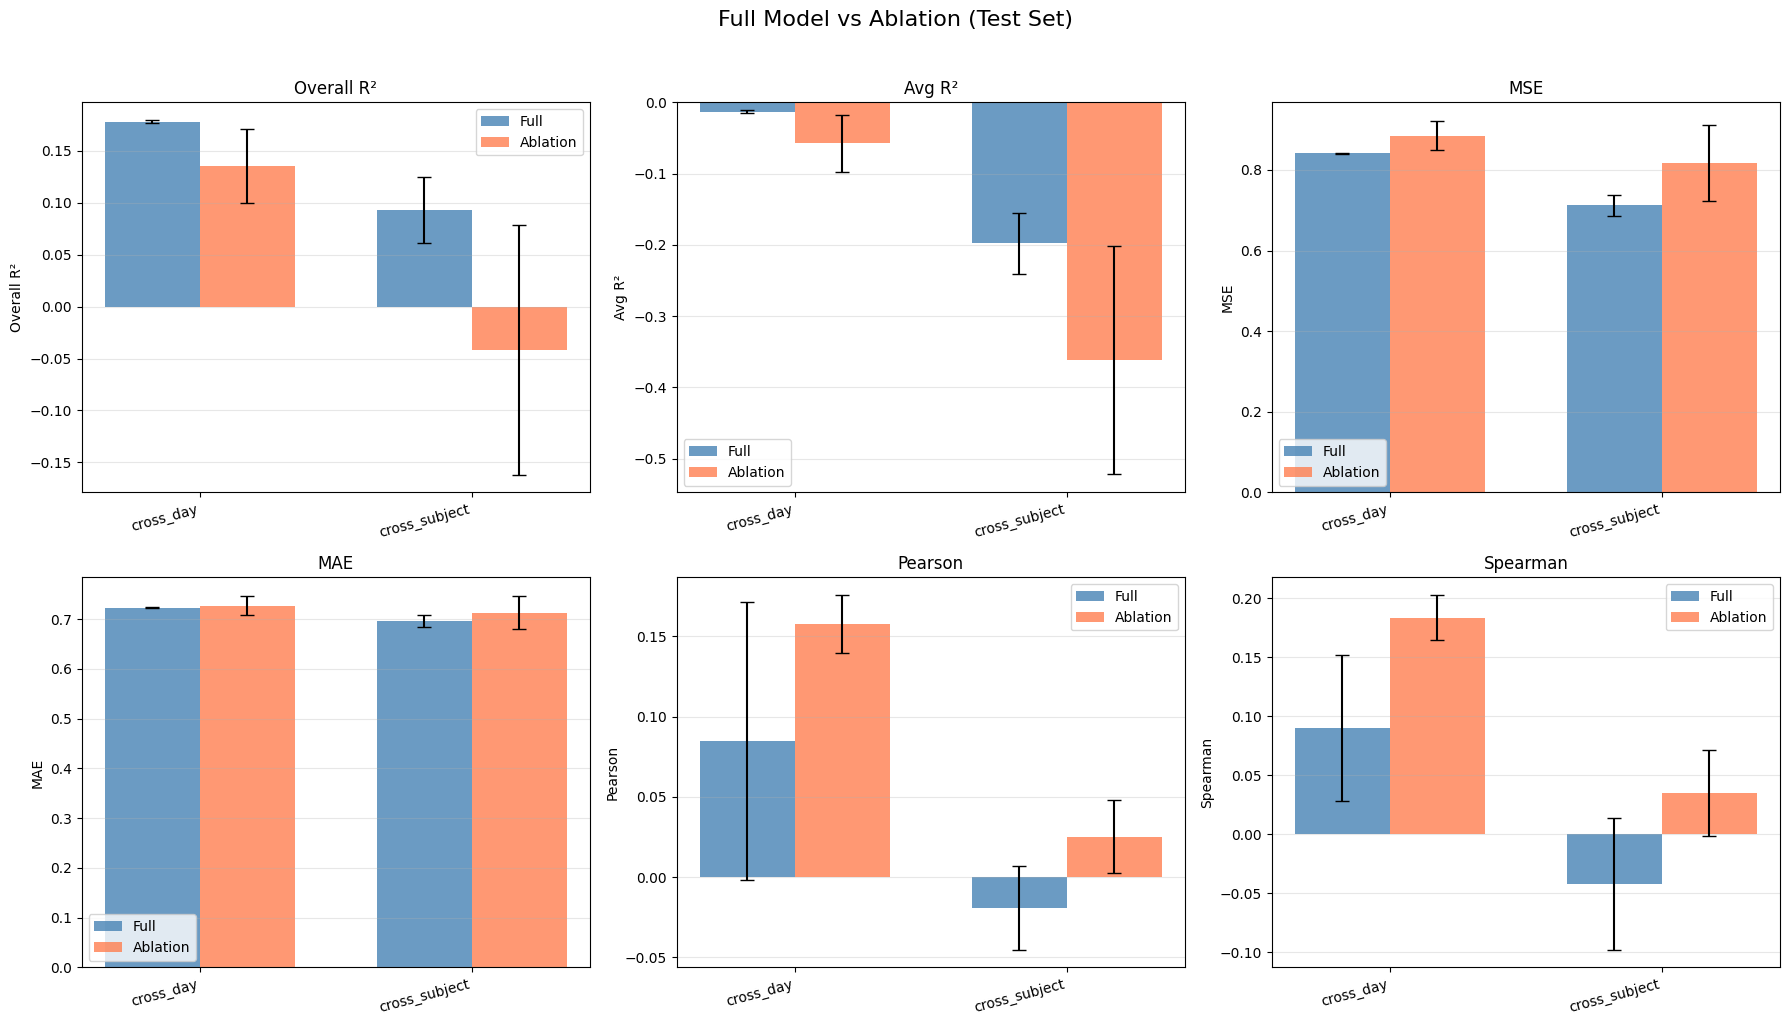

整体对比图已保存到 /root/zjm/cadt/ablation_comparison_overall.png


In [7]:
# ============================================================
# 5. 可视化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, metric in enumerate(overall_metrics):
    ax = axes[i]
    data_full = []
    data_ablation = []
    labels = []
    
    for split_mode in sorted(df['split_mode'].unique()):
        sub = df[df['split_mode'] == split_mode]
        full_vals = sub[sub['source'] == 'full'][metric].dropna().values
        abl_vals = sub[sub['source'] == 'ablation'][metric].dropna().values
        
        if len(full_vals) == 0 and len(abl_vals) == 0:
            continue
        
        data_full.append(full_vals)
        data_ablation.append(abl_vals)
        labels.append(split_mode)
    
    x = np.arange(len(labels))
    width = 0.35
    
    # 画柱状图（mean）+ 误差棒（sd）
    full_means = [np.mean(d) if len(d) > 0 else 0 for d in data_full]
    full_stds = [np.std(d, ddof=1) if len(d) > 1 else 0 for d in data_full]
    abl_means = [np.mean(d) if len(d) > 0 else 0 for d in data_ablation]
    abl_stds = [np.std(d, ddof=1) if len(d) > 1 else 0 for d in data_ablation]
    
    bars1 = ax.bar(x - width/2, full_means, width, yerr=full_stds, label='Full', capsize=5, color='steelblue', alpha=0.8)
    bars2 = ax.bar(x + width/2, abl_means, width, yerr=abl_stds, label='Ablation', capsize=5, color='coral', alpha=0.8)
    
    ax.set_ylabel(metric_names.get(metric, metric))
    ax.set_title(metric_names.get(metric, metric))
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=15, ha='right')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.suptitle("Full Model vs Ablation (Test Set)", fontsize=16, y=1.02)
plt.tight_layout()
# [disabled: not referenced by md] plt.savefig("/root/zjm/cadt/ablation_comparison_overall.png", dpi=150, bbox_inches='tight')
plt.show()
print("整体对比图已保存到 /root/zjm/cadt/ablation_comparison_overall.png")


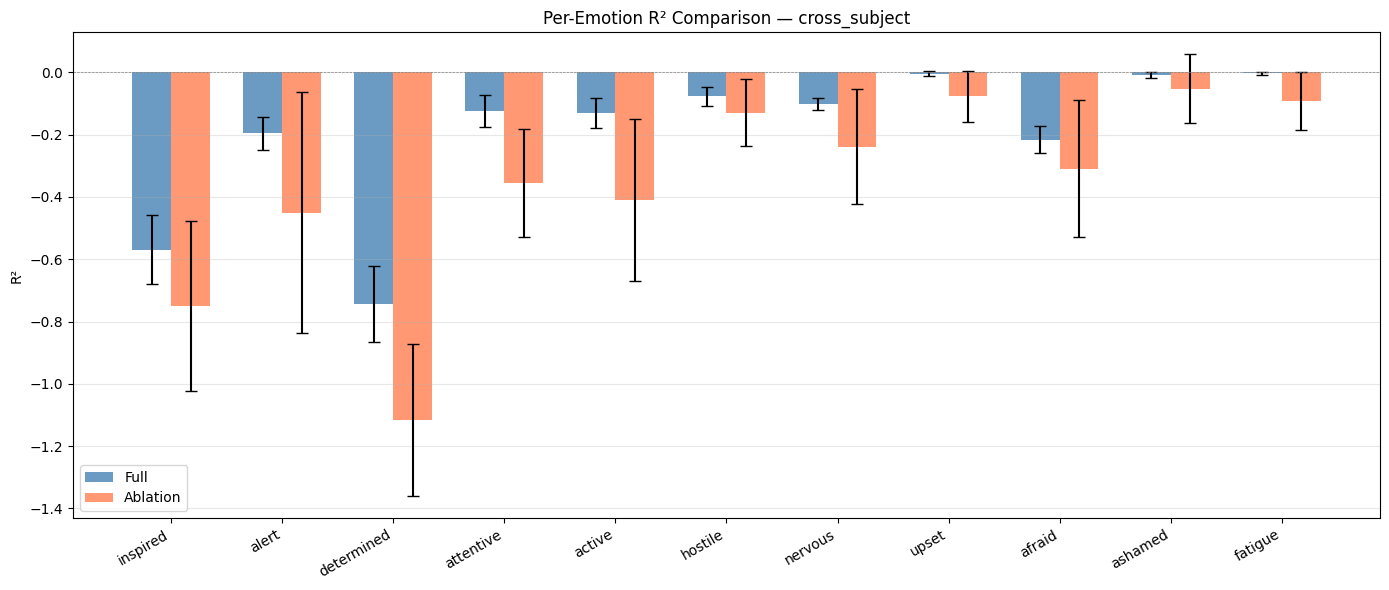

逐情绪 R² 对比图已保存到 /root/zjm/cadt/ablation_comparison_per_emotion_r2_cross_subject.png


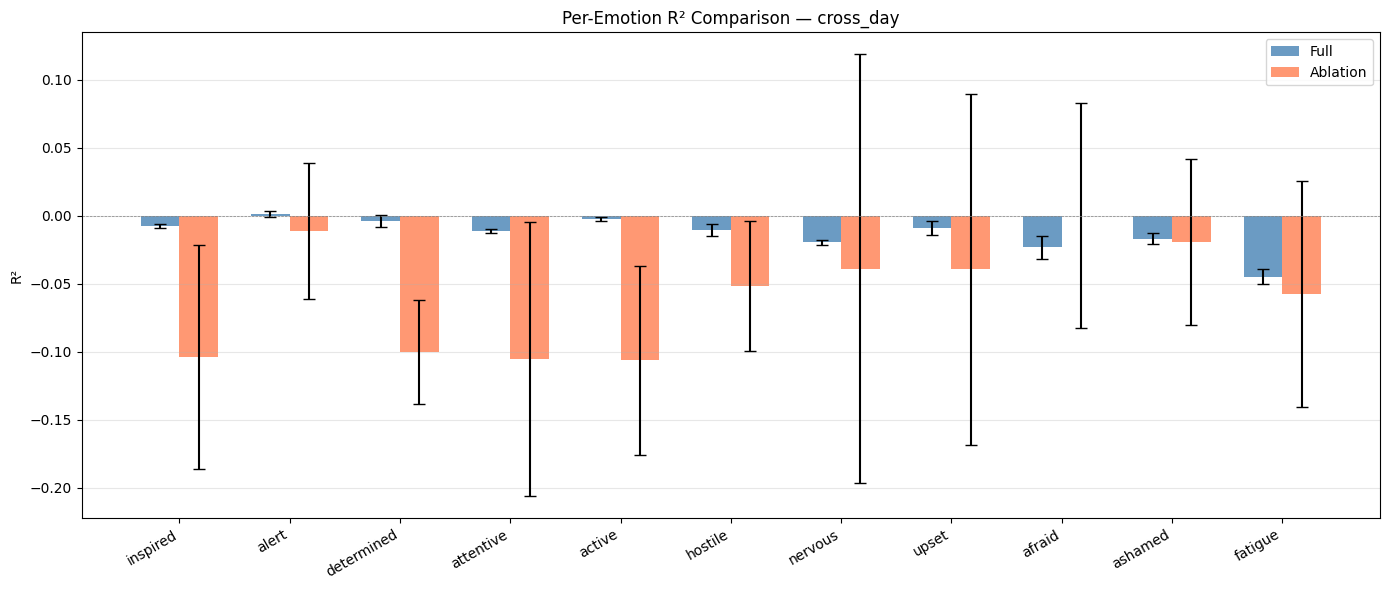

逐情绪 R² 对比图已保存到 /root/zjm/cadt/ablation_comparison_per_emotion_r2_cross_day.png


In [8]:
# ============================================================
# 6. 逐情绪维度 R² 可视化（分组柱状图）
# ============================================================
# 只画有消融数据的 split_mode
available_modes = emotion_df[emotion_df['source'] == 'ablation']['split_mode'].unique()

for split_mode in available_modes:
    sub = emotion_df[(emotion_df['split_mode'] == split_mode) & (emotion_df['metric'] == 'r2')]
    
    fig, ax = plt.subplots(figsize=(14, 6))
    x = np.arange(len(EMOTION_LABELS))
    width = 0.35
    
    full_means, full_stds, abl_means, abl_stds = [], [], [], []
    for emotion in EMOTION_LABELS:
        em_sub = sub[sub['emotion'] == emotion]
        f_vals = em_sub[em_sub['source'] == 'full']['value'].values
        a_vals = em_sub[em_sub['source'] == 'ablation']['value'].values
        full_means.append(np.mean(f_vals) if len(f_vals) > 0 else 0)
        full_stds.append(np.std(f_vals, ddof=1) if len(f_vals) > 1 else 0)
        abl_means.append(np.mean(a_vals) if len(a_vals) > 0 else 0)
        abl_stds.append(np.std(a_vals, ddof=1) if len(a_vals) > 1 else 0)
    
    ax.bar(x - width/2, full_means, width, yerr=full_stds, label='Full', capsize=4, color='steelblue', alpha=0.8)
    ax.bar(x + width/2, abl_means, width, yerr=abl_stds, label='Ablation', capsize=4, color='coral', alpha=0.8)
    
    ax.set_ylabel('R²')
    ax.set_title(f"Per-Emotion R² Comparison — {split_mode}")
    ax.set_xticks(x)
    ax.set_xticklabels(EMOTION_LABELS, rotation=30, ha='right')
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    save_path = f"/root/zjm/cadt/ablation_comparison_per_emotion_r2_{split_mode}.png"
    # [disabled: not referenced by md] plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"逐情绪 R² 对比图已保存到 {save_path}")